## Looking into the land constant data for SMAP

In [1]:
import pandas as pd 
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import os
import h5py

In [2]:
LMC_DIR = '/global/scratch/users/rubypercival/SMAP24/LMC'
import glob
lmc_matches = sorted(glob.glob(f'{LMC_DIR}/*.h5'))
assert lmc_matches, f'No .h5 file found in {LMC_DIR}'
file_path = lmc_matches[0]
print('Using LMC file:', file_path)
file=h5py.File(file_path,'r')

Using LMC file: /global/scratch/users/rubypercival/SMAP24/LMC/SMAP_L4_SM_lmc_00000000T000000_Vv8011_001.h5


In [3]:
def print_h5_structure(name, obj):
    print(name)

with h5py.File(file_path, 'r') as file:
    print("file structure:")
    file.visititems(print_h5_structure)

file structure:
EASE2_global_projection
Land-Model-Constants_Data
Land-Model-Constants_Data/cell_elevation
Land-Model-Constants_Data/cell_land_fraction
Land-Model-Constants_Data/clsm_cdcr1
Land-Model-Constants_Data/clsm_cdcr2
Land-Model-Constants_Data/clsm_dzgt1
Land-Model-Constants_Data/clsm_dzgt2
Land-Model-Constants_Data/clsm_dzgt3
Land-Model-Constants_Data/clsm_dzgt4
Land-Model-Constants_Data/clsm_dzgt5
Land-Model-Constants_Data/clsm_dzgt6
Land-Model-Constants_Data/clsm_dzpr
Land-Model-Constants_Data/clsm_dzrz
Land-Model-Constants_Data/clsm_dzsf
Land-Model-Constants_Data/clsm_dztsurf
Land-Model-Constants_Data/clsm_poros
Land-Model-Constants_Data/clsm_veghght
Land-Model-Constants_Data/clsm_wp
Land-Model-Constants_Data/mwrtm_bh
Land-Model-Constants_Data/mwrtm_bv
Land-Model-Constants_Data/mwrtm_clay
Land-Model-Constants_Data/mwrtm_lewt
Land-Model-Constants_Data/mwrtm_omega
Land-Model-Constants_Data/mwrtm_poros
Land-Model-Constants_Data/mwrtm_rghhmax
Land-Model-Constants_Data/mwrtm_rgh

In [4]:
with h5py.File(file_path, 'r') as file:
    dataset = file['Land-Model-Constants_Data/clsm_poros']
    print("shape:", dataset.shape)
    print("data type:", dataset.dtype)
    print("attributes:", dict(dataset.attrs))

shape: (1624, 3856)
data type: float32
attributes: {'DIMENSION_LABELS': array([b'y', b'x'], dtype='|S1'), 'DIMENSION_LIST': array([array([<HDF5 object reference>], dtype=object),
       array([<HDF5 object reference>], dtype=object)], dtype=object), '_FillValue': -9999.0, 'coordinates': b'/cell_lat /cell_lon', 'fmissing_value': -9999.0, 'grid_mapping': b'EASE2_global_projection', 'long_name': b'Catchment model: Soil porosity', 'missing_value': -9999.0, 'units': b'm3 m-3', 'valid_max': 0.93, 'valid_min': 0.3}


In [5]:
with h5py.File(file_path, 'r') as file:
    dataset = file['Land-Model-Constants_Data/mwrtm_poros']
    print("shape:", dataset.shape)
    print("data type:", dataset.dtype)
    print("attributes:", dict(dataset.attrs))

shape: (1624, 3856)
data type: float32
attributes: {'DIMENSION_LABELS': array([b'y', b'x'], dtype='|S1'), 'DIMENSION_LIST': array([array([<HDF5 object reference>], dtype=object),
       array([<HDF5 object reference>], dtype=object)], dtype=object), '_FillValue': -9999.0, 'coordinates': b'/cell_lat /cell_lon', 'fmissing_value': -9999.0, 'grid_mapping': b'EASE2_global_projection', 'long_name': b'Microwave radiative transfer model: Porosity', 'missing_value': -9999.0, 'units': b'm3 m-3', 'valid_max': 0.93, 'valid_min': 0.3}


In [6]:
with h5py.File(file_path, 'r') as f:
    catchment_model_porosity= f['Land-Model-Constants_Data/clsm_poros'][:]
    microwave_model_porosity= f['Land-Model-Constants_Data/mwrtm_poros'][:]
    cell_lat = f['cell_lat'][:]
    cell_lon = f['cell_lon'][:]
    time = f['time'][:]

#.ravel() will flatten multi D arrays to 1D
porosity_df = pd.DataFrame({'latitude': cell_lat.ravel(),
                   'longitude': cell_lon.ravel(),
                   'time': np.full(cell_lat.size, time[0]),  #same time for all points because one file has one time for everything
                   'catchment_model_porosity': catchment_model_porosity.ravel(),
                   'microwave_model_porosity': microwave_model_porosity.ravel()})

porosity_df['datetime'] = pd.to_datetime(porosity_df['time'], unit='s', origin='2000-01-01 11:58:55.816')
porosity_df.drop(columns='time', inplace=True)

In [7]:
porosity_df

,latitude,longitude,catchment_model_porosity,microwave_model_porosity,datetime
0,84.656441,-179.953323,-9999.0,-9999.0,2024-10-01 23:58:55
1,84.656441,-179.859970,-9999.0,-9999.0,2024-10-01 23:58:55
2,84.656441,-179.766602,-9999.0,-9999.0,2024-10-01 23:58:55
3,84.656441,-179.673248,-9999.0,-9999.0,2024-10-01 23:58:55
4,84.656441,-179.579880,-9999.0,-9999.0,2024-10-01 23:58:55
...,...,...,...,...,...
6262139,-84.656441,179.579880,-9999.0,-9999.0,2024-10-01 23:58:55
6262140,-84.656441,179.673248,-9999.0,-9999.0,2024-10-01 23:58:55
6262141,-84.656441,179.766602,-9999.0,-9999.0,2024-10-01 23:58:55
6262142,-84.656441,179.859970,-9999.0,-9999.0,2024-10-01 23:58:55


In [8]:
lon_min, lon_max= -104,-80
lat_min, lat_max =36,49

midwest_porosity_df = porosity_df[(porosity_df['latitude'] > lat_min) & (porosity_df['latitude'] < lat_max) &
(porosity_df['longitude'] > lon_min) & (porosity_df['longitude'] < lon_max)]

midwest_porosity_df

,latitude,longitude,catchment_model_porosity,microwave_model_porosity,datetime
764302,48.951267,-103.957474,0.3963,0.4351,2024-10-01 23:58:55
764303,48.951267,-103.864113,0.4352,0.4584,2024-10-01 23:58:55
764304,48.951267,-103.770752,0.4352,0.4584,2024-10-01 23:58:55
764305,48.951267,-103.677391,0.4352,0.4584,2024-10-01 23:58:55
764306,48.951267,-103.584030,0.4352,0.4584,2024-10-01 23:58:55
...,...,...,...,...,...
1285114,36.070938,-80.430504,0.4942,0.4063,2024-10-01 23:58:55
1285115,36.070938,-80.337143,0.4942,0.4063,2024-10-01 23:58:55
1285116,36.070938,-80.243782,0.4554,0.4457,2024-10-01 23:58:55
1285117,36.070938,-80.150421,0.5463,0.4063,2024-10-01 23:58:55


In [9]:
missing_value = -9999

midwest_porosity_df['catchment_model_porosity'] = midwest_porosity_df['catchment_model_porosity'].replace(missing_value, np.nan)
midwest_porosity_df['microwave_model_porosity'] = midwest_porosity_df['microwave_model_porosity'].replace(missing_value, np.nan)
midwest_porosity_df = midwest_porosity_df.dropna(subset=['catchment_model_porosity', 'microwave_model_porosity'])

In [10]:
midwest_porosity_df

,latitude,longitude,catchment_model_porosity,microwave_model_porosity,datetime
764302,48.951267,-103.957474,0.3963,0.4351,2024-10-01 23:58:55
764303,48.951267,-103.864113,0.4352,0.4584,2024-10-01 23:58:55
764304,48.951267,-103.770752,0.4352,0.4584,2024-10-01 23:58:55
764305,48.951267,-103.677391,0.4352,0.4584,2024-10-01 23:58:55
764306,48.951267,-103.584030,0.4352,0.4584,2024-10-01 23:58:55
...,...,...,...,...,...
1285114,36.070938,-80.430504,0.4942,0.4063,2024-10-01 23:58:55
1285115,36.070938,-80.337143,0.4942,0.4063,2024-10-01 23:58:55
1285116,36.070938,-80.243782,0.4554,0.4457,2024-10-01 23:58:55
1285117,36.070938,-80.150421,0.5463,0.4063,2024-10-01 23:58:55


In [11]:
print('Statistics for the catchment model porosity are:')
midwest_porosity_df['catchment_model_porosity'].describe()

Statistics for the catchment model porosity are:


count    32612.000000
mean         0.469926
std          0.092451
min          0.374100
25%          0.421400
50%          0.452700
75%          0.494200
max          0.930000
Name: catchment_model_porosity, dtype: float64

In [12]:
print('Statistics for the microwave radiative transfer model porosity are:')
midwest_porosity_df['microwave_model_porosity'].describe()

Statistics for the microwave radiative transfer model porosity are:


count    32612.000000
mean         0.474784
std          0.087047
min          0.374100
25%          0.440000
50%          0.458400
75%          0.485700
max          0.930000
Name: microwave_model_porosity, dtype: float64

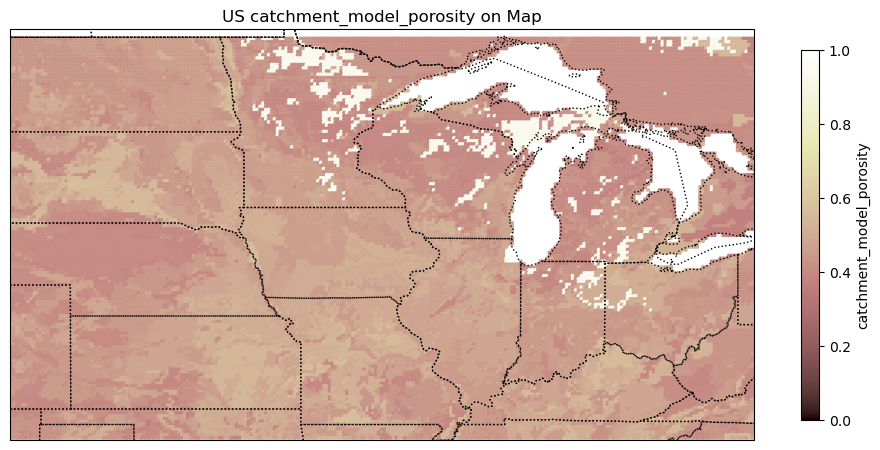

In [13]:
#plotting catchment model porosity first
sm_variable ='catchment_model_porosity'

plt.figure(figsize=(12, 8))
ax = plt.axes(projection=ccrs.PlateCarree())
ax.add_feature(cfeature.COASTLINE)
ax.add_feature(cfeature.BORDERS, linestyle=':')
ax.add_feature(cfeature.STATES, linestyle=':')

sc = ax.scatter(midwest_porosity_df['longitude'], midwest_porosity_df['latitude'],
                c=midwest_porosity_df[sm_variable],
                cmap='pink',
                s=4,
                transform=ccrs.PlateCarree(),
               vmin=0, 
               vmax=1)


cbar = plt.colorbar(sc, ax=ax, orientation='vertical', shrink=0.6)
cbar.set_label(f'{sm_variable}')

ax.set_title(f'US {sm_variable} on Map')
ax.set_extent([lon_min, lon_max, lat_min, lat_max])

plt.show()

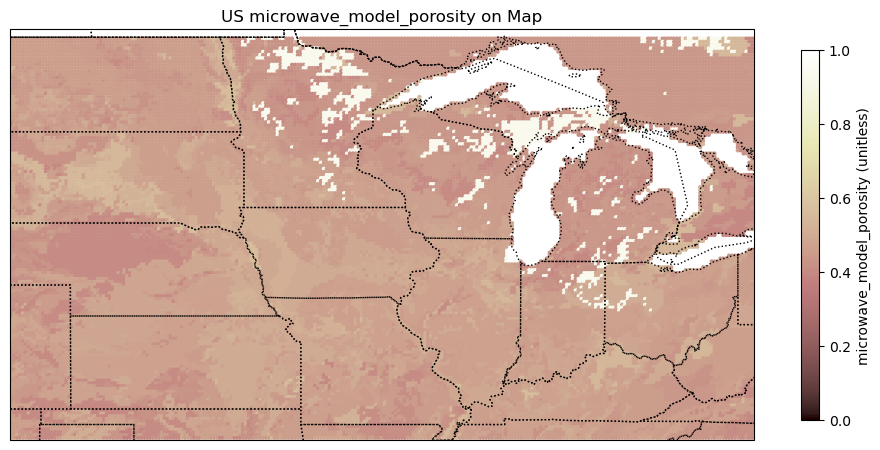

In [14]:
#plotting catchment model porosity first

sm_variable ='microwave_model_porosity'

plt.figure(figsize=(12, 8))
ax = plt.axes(projection=ccrs.PlateCarree())
ax.add_feature(cfeature.COASTLINE)
ax.add_feature(cfeature.BORDERS, linestyle=':')
ax.add_feature(cfeature.STATES, linestyle=':')

sc = ax.scatter(midwest_porosity_df['longitude'], midwest_porosity_df['latitude'],
                c=midwest_porosity_df[sm_variable],
                cmap='pink',
                s=4,
                vmin=0,
                vmax=1,
                transform=ccrs.PlateCarree())


cbar = plt.colorbar(sc, ax=ax, orientation='vertical', shrink=0.6)
cbar.set_label(f'{sm_variable} (unitless)')

ax.set_title(f'US {sm_variable} on Map')
ax.set_extent([lon_min, lon_max, lat_min, lat_max])

plt.show()

In [15]:
print([v for v in dir() if not v.startswith('_')])

['In', 'LMC_DIR', 'NamespaceMagics', 'Out', 'ax', 'catchment_model_porosity', 'cbar', 'ccrs', 'cell_lat', 'cell_lon', 'cfeature', 'dataset', 'exit', 'f', 'file', 'file_path', 'get_ipython', 'glob', 'h5py', 'json', 'lat_max', 'lat_min', 'lmc_matches', 'lon_max', 'lon_min', 'microwave_model_porosity', 'midwest_porosity_df', 'missing_value', 'np', 'open', 'os', 'pd', 'plt', 'porosity_df', 'print_h5_structure', 'quit', 'sc', 'sm_variable', 'sys', 'time', 'xr']


In [17]:
midwest_porosity_df['diff_c-m'] = midwest_porosity_df['catchment_model_porosity'] - midwest_porosity_df['microwave_model_porosity']
midwest_porosity_df

,latitude,longitude,catchment_model_porosity,microwave_model_porosity,datetime,diff_c-m
764302,48.951267,-103.957474,0.3963,0.4351,2024-10-01 23:58:55,-0.0388
764303,48.951267,-103.864113,0.4352,0.4584,2024-10-01 23:58:55,-0.0232
764304,48.951267,-103.770752,0.4352,0.4584,2024-10-01 23:58:55,-0.0232
764305,48.951267,-103.677391,0.4352,0.4584,2024-10-01 23:58:55,-0.0232
764306,48.951267,-103.584030,0.4352,0.4584,2024-10-01 23:58:55,-0.0232
...,...,...,...,...,...,...
1285114,36.070938,-80.430504,0.4942,0.4063,2024-10-01 23:58:55,0.0879
1285115,36.070938,-80.337143,0.4942,0.4063,2024-10-01 23:58:55,0.0879
1285116,36.070938,-80.243782,0.4554,0.4457,2024-10-01 23:58:55,0.0097
1285117,36.070938,-80.150421,0.5463,0.4063,2024-10-01 23:58:55,0.1400


In [28]:
print('sm_poros_df date range:', sm_poros_df['datetime_x'].min(), 'to', sm_poros_df['datetime_x'].max())
print('Unique months:', sorted(sm_poros_df['datetime_x'].dt.to_period('M').unique()))

sm_poros_df date range: 2024-02-29 22:28:55 to 2024-07-31 22:28:55
Unique months: [Period('2024-02', 'M'), Period('2024-03', 'M'), Period('2024-04', 'M'), Period('2024-05', 'M'), Period('2024-06', 'M'), Period('2024-07', 'M')]


In [20]:
gpd_df = pd.read_parquet('/global/scratch/users/rubypercival/SMAP24/parquet/SMAP_GPD_mar-jul24.parquet', engine='pyarrow')
print('GPD date range:', gpd_df['datetime'].min(), 'to', gpd_df['datetime'].max())

GPD date range: 2024-02-29 22:28:55 to 2024-07-31 22:28:55


In [21]:
print('Statistics for the catchment model - radiative transfer model:')
midwest_porosity_df['diff_c-m'].describe()

Statistics for the catchment model - radiative transfer model:


count    32612.000000
mean        -0.004858
std          0.028938
min         -0.174800
25%         -0.025200
50%          0.000000
75%          0.008700
max          0.159200
Name: diff_c-m, dtype: float64

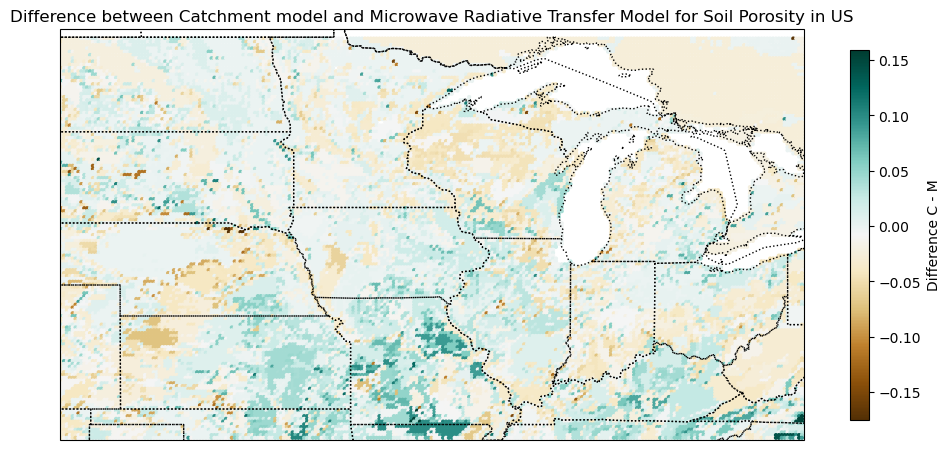

In [22]:
plt.figure(figsize=(12, 8))
ax = plt.axes(projection=ccrs.PlateCarree())
ax.add_feature(cfeature.COASTLINE)
ax.add_feature(cfeature.BORDERS, linestyle=':')
ax.add_feature(cfeature.STATES, linestyle=':')

sc = ax.scatter(midwest_porosity_df['longitude'], midwest_porosity_df['latitude'],
                c=midwest_porosity_df['diff_c-m'],
                cmap='BrBG',
                s=4,
                transform=ccrs.PlateCarree())


cbar = plt.colorbar(sc, ax=ax, orientation='vertical', shrink=0.6)
cbar.set_label(f'Difference C - M')

ax.set_title(f'Difference between Catchment model and Microwave Radiative Transfer Model for Soil Porosity in US')
ax.set_extent([lon_min, lon_max, lat_min, lat_max])

plt.show()

### now insert SMAP soil moisture data to look at WFPS

In [23]:
smap_file = '/global/scratch/users/rubypercival/SMAP24/parquet/SMAP_GPD_mar-jul24.parquet'
smap_df=pd.read_parquet(smap_file, engine='pyarrow')


In [24]:
sm_poros_df = pd.merge(
    smap_df,
    midwest_porosity_df,
    on=['latitude', 'longitude'],
    how='inner')            

In [25]:
sm_poros_df= sm_poros_df.drop(columns=['datetime_y'])

In [26]:
sm_poros_df['WFPS_c'] = sm_poros_df['sm_surface']/sm_poros_df['catchment_model_porosity']
sm_poros_df['WFPS_m'] = sm_poros_df['sm_surface']/sm_poros_df['microwave_model_porosity']

In [27]:
sm_poros_df

,latitude,longitude,sm_surface,sm_rootzone,surface_temp,soil_temp_layer1,LAI,datetime_x,catchment_model_porosity,microwave_model_porosity,diff_c-m,WFPS_c,WFPS_m
0,48.951267,-103.957474,0.092959,0.115514,282.461212,273.161682,0.042729,2024-02-29 22:28:55,0.3963,0.4351,-0.0388,0.234567,0.213649
1,48.951267,-103.864113,0.166994,0.197637,282.129181,273.091370,0.036702,2024-02-29 22:28:55,0.4352,0.4584,-0.0232,0.383719,0.364298
2,48.951267,-103.770752,0.168032,0.197454,281.304840,272.724182,0.030683,2024-02-29 22:28:55,0.4352,0.4584,-0.0232,0.386103,0.366562
3,48.951267,-103.677391,0.166872,0.200200,281.550812,272.728088,0.029180,2024-02-29 22:28:55,0.4352,0.4584,-0.0232,0.383438,0.364032
4,48.951267,-103.584030,0.165163,0.201177,281.975861,272.935120,0.029721,2024-02-29 22:28:55,0.4352,0.4584,-0.0232,0.379511,0.360304
...,...,...,...,...,...,...,...,...,...,...,...,...,...
39949695,36.070938,-80.430504,0.273520,0.314829,302.614075,301.055420,3.516604,2024-07-31 22:28:55,0.4942,0.4063,0.0879,0.553459,0.673196
39949696,36.070938,-80.337143,0.286581,0.302500,302.606262,301.219482,1.901370,2024-07-31 22:28:55,0.4942,0.4063,0.0879,0.579889,0.705344
39949697,36.070938,-80.243782,0.274618,0.291880,303.168762,302.114014,1.140140,2024-07-31 22:28:55,0.4554,0.4457,0.0097,0.603027,0.616150
39949698,36.070938,-80.150421,0.327963,0.358408,302.578918,301.215576,1.942386,2024-07-31 22:28:55,0.5463,0.4063,0.1400,0.600335,0.807194


In [29]:
sm_poros_df['WFPS_c'].describe()

count    3.994970e+07
mean     5.269501e-01
std      1.749480e-01
min      1.521821e-02
25%      4.063894e-01
50%      5.313479e-01
75%      6.610589e-01
max      9.999550e-01
Name: WFPS_c, dtype: float64

In [30]:
sm_poros_df['WFPS_m'].describe()

count    3.994970e+07
mean     5.243490e-01
std      1.850925e-01
min      1.426443e-02
25%      3.929948e-01
50%      5.236714e-01
75%      6.627780e-01
max      1.261420e+00
Name: WFPS_m, dtype: float64

In [31]:
sm_poros_df['WFPS_diff'] = sm_poros_df['WFPS_c']-sm_poros_df['WFPS_m']

In [32]:
regional_mean = sm_poros_df.groupby(['latitude', 'longitude'])[['WFPS_c', 'WFPS_m', 'WFPS_diff']].mean().reset_index()
regional_mean

,latitude,longitude,WFPS_c,WFPS_m,WFPS_diff
0,36.070938,-103.957474,0.324012,0.295526,0.028485
1,36.070938,-103.864113,0.380333,0.371041,0.009293
2,36.070938,-103.770752,0.347322,0.349939,-0.002617
3,36.070938,-103.677391,0.333597,0.328413,0.005184
4,36.070938,-103.584030,0.261699,0.238692,0.023007
...,...,...,...,...,...
32607,48.951267,-80.430504,0.780165,0.781884,-0.001719
32608,48.951267,-80.337143,0.513709,0.352816,0.160894
32609,48.951267,-80.243782,0.476734,0.455081,0.021653
32610,48.951267,-80.150421,0.474481,0.452930,0.021551


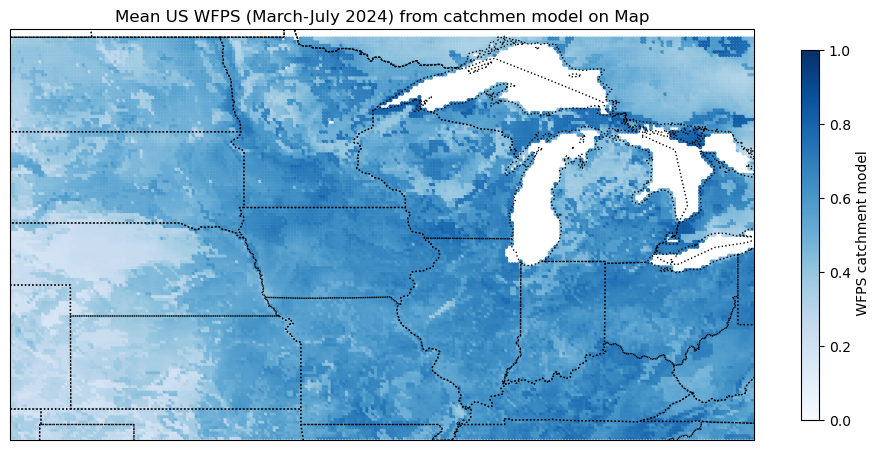

In [33]:
#plotting catchment model WFPS first

plt.figure(figsize=(12, 8))
ax = plt.axes(projection=ccrs.PlateCarree())
ax.add_feature(cfeature.COASTLINE)
ax.add_feature(cfeature.BORDERS, linestyle=':')
ax.add_feature(cfeature.STATES, linestyle=':')

sc = ax.scatter(regional_mean['longitude'], regional_mean['latitude'],
                c=regional_mean['WFPS_c'],
                cmap='Blues',
                s=4,
                transform=ccrs.PlateCarree(),
               vmin=0, 
               vmax=1)

cbar = plt.colorbar(sc, ax=ax, orientation='vertical', shrink=0.6)
cbar.set_label(f' WFPS catchment model')

ax.set_title(f'Mean US WFPS (March-July 2024) from catchmen model on Map')
ax.set_extent([lon_min, lon_max, lat_min, lat_max])

plt.show()

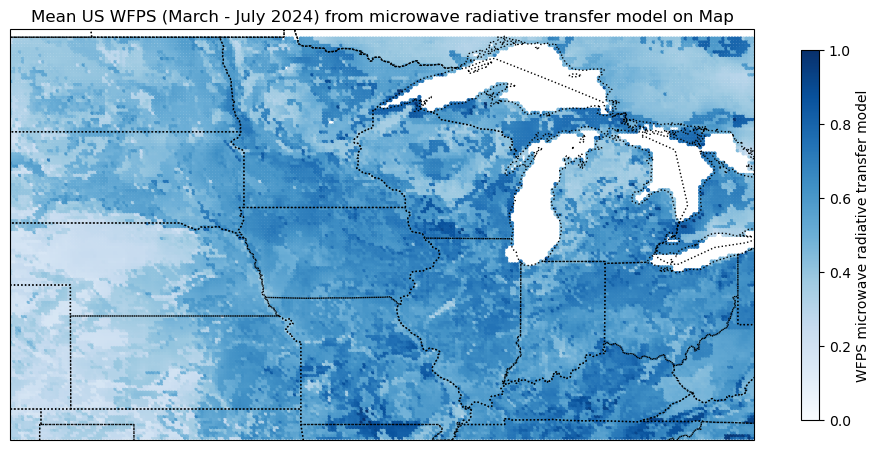

In [34]:
#plotting microwave model WFPS 

plt.figure(figsize=(12, 8))
ax = plt.axes(projection=ccrs.PlateCarree())
ax.add_feature(cfeature.COASTLINE)
ax.add_feature(cfeature.BORDERS, linestyle=':')
ax.add_feature(cfeature.STATES, linestyle=':')

sc = ax.scatter(regional_mean['longitude'], regional_mean['latitude'],
                c=regional_mean['WFPS_m'],
                cmap='Blues',
                s=4,
                transform=ccrs.PlateCarree(),
               vmin=0, 
               vmax=1)

cbar = plt.colorbar(sc, ax=ax, orientation='vertical', shrink=0.6)
cbar.set_label(f'WFPS microwave radiative transfer model')

ax.set_title(f'Mean US WFPS (March - July 2024) from microwave radiative transfer model on Map')
ax.set_extent([lon_min, lon_max, lat_min, lat_max])

plt.show()

In [35]:
sm_poros_df['WFPS_diff'].describe()

count    3.994970e+07
mean     2.600809e-03
std      3.612258e-02
min     -3.508618e-01
25%     -7.340938e-03
50%      0.000000e+00
75%      2.375764e-02
max      3.044638e-01
Name: WFPS_diff, dtype: float64

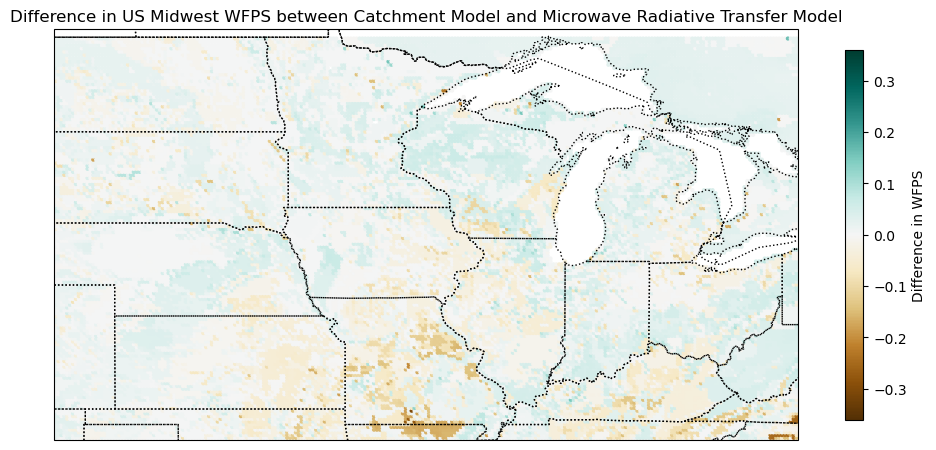

In [36]:
plt.figure(figsize=(12, 8))
ax = plt.axes(projection=ccrs.PlateCarree())
ax.add_feature(cfeature.COASTLINE)
ax.add_feature(cfeature.BORDERS, linestyle=':')
ax.add_feature(cfeature.STATES, linestyle=':')

sc = ax.scatter(regional_mean['longitude'], regional_mean['latitude'],
                c=regional_mean['WFPS_diff'],
                cmap='BrBG',
                s=4,
                transform=ccrs.PlateCarree(), 
               vmin=-0.36,
                vmax=0.36)

cbar = plt.colorbar(sc, ax=ax, orientation='vertical', shrink=0.6)
cbar.set_label(f'Difference in WFPS')

ax.set_title(f'Difference in US Midwest WFPS between Catchment Model and Microwave Radiative Transfer Model')
ax.set_extent([lon_min, lon_max, lat_min, lat_max])

plt.show()

In [38]:
precip_file = '/global/scratch/users/rubypercival/0.1x0.1_deg_gridded_datasets/gridded_and_crop_filtered/PPS_03-07_0.1x0.1gridded_cropfiltered_MCD12Q1mask_2024.parquet'
precip = pd.read_parquet(precip_file, engine='pyarrow')

### Making a parquet file with land model constants
will include 
* clsm_poros
* mwrtm_poros
* cell_lat
* cell_lon
* time

In [41]:
midwest_porosity_df

,latitude,longitude,catchment_model_porosity,microwave_model_porosity,datetime,diff_c-m
764302,48.951267,-103.957474,0.3963,0.4351,2024-10-01 23:58:55,-0.0388
764303,48.951267,-103.864113,0.4352,0.4584,2024-10-01 23:58:55,-0.0232
764304,48.951267,-103.770752,0.4352,0.4584,2024-10-01 23:58:55,-0.0232
764305,48.951267,-103.677391,0.4352,0.4584,2024-10-01 23:58:55,-0.0232
764306,48.951267,-103.584030,0.4352,0.4584,2024-10-01 23:58:55,-0.0232
...,...,...,...,...,...,...
1285114,36.070938,-80.430504,0.4942,0.4063,2024-10-01 23:58:55,0.0879
1285115,36.070938,-80.337143,0.4942,0.4063,2024-10-01 23:58:55,0.0879
1285116,36.070938,-80.243782,0.4554,0.4457,2024-10-01 23:58:55,0.0097
1285117,36.070938,-80.150421,0.5463,0.4063,2024-10-01 23:58:55,0.1400


In [42]:
output_file = '/global/scratch/users/rubypercival/SMAP24/midwest_soil_moisture_poros_WFPS.parquet'
sm_poros_df.to_parquet(output_file, engine='pyarrow')
